You need to run each pip install in a separate block for it to work (not sure why)

In [1]:
#pip install pyblp
#pip install pandas
#pip install pyRVtest
#pip install matplotlib
#pip install Jinja2

In [2]:
import pyblp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyRVtest
from IPython.display import display

import io
import re
from contextlib import redirect_stdout


pyblp.options.digits = 5
pyblp.options.verbose = False
pyblp.__version__

'1.1.2'

In [3]:
#choose the dataset you want
#product_data = pd.read_csv("LETF_product_month_level_v3.csv")
#product_data = pd.read_csv("LETF_product_month_level_v3_altSample.csv")
product_data = pd.read_csv("nonLev_funds_product_month_level_v2_patched.csv", low_memory=False)
#product_data = pd.read_csv("LETF_product_month_level_v4_altSample.csv")
#product_data = pd.read_csv("LETF_product_month_level_v6.csv")

# To drop missing values
# product_data.dropna(inplace=True)

# need to create unique market id
product_data["market_ids"] = product_data.groupby(["month_t"]).ngroup()+1

display(product_data[["month_t", "market_ids"]].drop_duplicates().sort_values("market_ids").head())

# create some variable needed for estimation
product_data["log_product_fund_age"] = np.log(product_data["product_fund_age"])
product_data["product_tracking_err"] = abs(product_data["product_tracking_err"])
product_data["broad_specialized_ind"] = (product_data["broad_specialized"] ==  "broad-based").astype(int)

# drop NA
product_data = product_data.dropna(subset=['Conduct_IV_csent_index_resid'])
#product_data = product_data.dropna(subset=['BLP_IV_hausman_mgmt_fee'])
#product_data = product_data[~((product_data["firm_f"].str.contains("Rydex", case=False, na=False)) & (product_data["product_L1_mtna"] < 10))]
#product_data = product_data[~((product_data["firm_f"].str.contains("ProFunds", case=False, na=False)) & (product_data["product_L1_mtna"] < 10))]

#product_data = product_data.loc[product_data['market_m_index'] != 'SML']

#display(product_data["Conduct_IV_sent_pls_resid"].describe())

# cluster SE
product_data['clustering_ids'] = product_data.market_ids

display(product_data["market_ids"].describe())


,month_t,market_ids
509,1994.000000,1
510,1994.083333,2
511,1994.166667,3
512,1994.250000,4
513,1994.333333,5


count    546665.000000
mean        266.649211
std          79.852621
min           1.000000
25%         214.000000
50%         279.000000
75%         333.000000
max         382.000000
Name: market_ids, dtype: float64

In [4]:
# need to rename to prices and shares  and IV for using built in package below
product_data = product_data.rename(columns={
    'product_exp_ratio': 'prices',
    'market_share': 'shares_old',
    'BLP_IV_hausman_exp_ratio': 'demand_instruments0',
    'BLP_IV_hausman_exp_ratio_x_broad': 'demand_instruments1',
    #'IV2_exp_ratio_vw': 'demand_instruments1', # This is not needed for logit which only requires one IV for the price
    'firm_f': 'firm_ids',
    'product_j': 'product_ids',
})

# need to recompute market share to make sure they sum up to 1 (PyBLP needs they sum up to less than 1!)
product_data["shares"] = (
    #product_data["product_mtna"] / product_data.groupby("market_ids")["product_mtna"].transform("sum")
    product_data["product_mtna"] / product_data["market_share_m_denom_alt1"]
)

product_data = product_data.loc[product_data['shares'] >= 0.0001]
product_data = product_data.loc[product_data['month_t'] >=2010]
product_data = product_data.loc[product_data['month_t'] <=(2024+8/12)]
product_data = product_data[product_data['prefer'].isin([1,2,3,4,5])]
product_data = product_data.loc[product_data['prices'] > 0] ### Prices equal to zero inside outside option

#product_data['firm_ids'] = np.where(product_data['firm_ids']=='ProFunds', 'ProShares', product_data['firm_ids'])

# demand rotator and its instrument
product_data["rotator"] = (
    product_data["Conduct_IV_neg_vw_ind_resid_1m"] + product_data["Conduct_IV_neg_vw_ind_resid_2to5m"] + product_data["Conduct_IV_neg_vw_ind_resid_6to12m"]
)

'''
product_data["demand_instruments4"] = (
    product_data["demand_instruments0"] * product_data["rotator"]
)

product_data["demand_instruments5"] = (
    product_data["demand_instruments1"] * product_data["rotator"]
)

product_data["demand_instruments6"] = (
    product_data["demand_instruments2"] * product_data["rotator"]
)

product_data["demand_instruments7"] = (
    product_data["demand_instruments3"] * product_data["rotator"]
)
'''

display(product_data["prices"].describe())
display(product_data["shares_old"].describe())
display(product_data["shares"].describe())
display(product_data["product_mtna"].describe())
display(product_data["firm_ids"].describe())
display(product_data["product_ids"].describe())

display(product_data.info())
display(product_data.head(10))

count    108300.000000
mean          0.285486
std           0.263334
min           0.010000
25%           0.080000
50%           0.200000
75%           0.440000
max           2.850000
Name: prices, dtype: float64

count    108300.000000
mean          0.001391
std           0.003518
min           0.000102
25%           0.000182
50%           0.000386
75%           0.001053
max           0.051506
Name: shares_old, dtype: float64

count    108300.000000
mean          0.001347
std           0.003407
min           0.000100
25%           0.000176
50%           0.000374
75%           0.001019
max           0.049652
Name: shares, dtype: float64

count    108300.000000
mean       9201.351229
std       28069.819713
min         175.500000
25%        1056.075000
50%        2292.950000
75%        6416.150000
max      700879.400000
Name: product_mtna, dtype: float64

count       108300
unique          90
top       Vanguard
freq         26697
Name: firm_ids, dtype: object

count    108300.000000
mean      38579.719381
std       19792.226957
min        3620.000000
25%       25138.000000
50%       35773.000000
75%       50970.000000
max      102153.000000
Name: product_ids, dtype: float64

<class 'pandas.core.frame.DataFrame'>
Index: 108300 entries, 1010 to 578315
Data columns (total 98 columns):
 #   Column                              Non-Null Count   Dtype  
---  ------                              --------------   -----  
 0   product_ids                         108300 non-null  int64  
 1   month_t                             108300 non-null  float64
 2   quarter                             108300 non-null  float64
 3   market_m_index                      108300 non-null  object 
 4   firm_f_old                          100529 non-null  object 
 5   market_m_cluster                    108300 non-null  int64  
 6   market_m_index_mret                 108300 non-null  float64
 7   product_fund_name                   108300 non-null  object 
 8   product_mnav                        108300 non-null  float64
 9   product_mret                        108298 non-null  float64
 10  product_mtna                        108300 non-null  float64
 11  product_L1_mtna             

None

,product_ids,month_t,quarter,market_m_index,firm_f_old,market_m_cluster,market_m_index_mret,product_fund_name,product_mnav,product_mret,...,product_exp_ratio_bkpt,broad_specialized,demand_instruments1,product_exp_ratio_x_broad,market_ids,log_product_fund_age,broad_specialized_ind,clustering_ids,shares,rotator
1010,3620,2011.333333,2011.25,M1WDLCT,AOF,27,-0.018388,AdvisorOne Funds: Amerigo Fund; Class N Shares,14.23,-0.014543,...,0.12,specialized,0.0,0.0,209,2.621039,0,209,0.000225,0.025848
1011,3620,2011.416667,2011.25,M1WDLCT,AOF,27,-0.016806,AdvisorOne Funds: Amerigo Fund; Class N Shares,13.96,-0.018974,...,0.12,specialized,0.0,0.0,210,2.627081,0,210,0.000222,0.018962
1012,3620,2011.500000,2011.50,M1WDLCT,AOF,27,-0.014387,AdvisorOne Funds: Amerigo Fund; Class N Shares,13.64,-0.022923,...,0.11,specialized,0.0,0.0,211,2.633087,0,211,0.000211,0.004892
1013,3620,2011.583333,2011.50,M1WDLCT,AOF,27,-0.073383,AdvisorOne Funds: Amerigo Fund; Class N Shares,12.63,-0.074047,...,0.11,specialized,0.0,0.0,212,2.639057,0,212,0.000205,0.026641
1014,3620,2011.666667,2011.50,M1WDLCT,AOF,27,-0.094343,AdvisorOne Funds: Amerigo Fund; Class N Shares,11.21,-0.112431,...,0.11,specialized,0.0,0.0,213,2.644992,0,213,0.000196,0.041708
1015,3620,2011.750000,2011.75,M1WDLCT,AOF,27,0.106421,AdvisorOne Funds: Amerigo Fund; Class N Shares,12.62,0.125781,...,0.11,specialized,0.0,0.0,214,2.650892,0,214,0.000197,0.041700
1016,3620,2011.833333,2011.75,M1WDLCT,AOF,27,-0.030246,AdvisorOne Funds: Amerigo Fund; Class N Shares,12.54,-0.006339,...,0.11,specialized,0.0,0.0,215,2.656757,0,215,0.000194,0.071850
1017,3620,2011.916667,2011.75,M1WDLCT,AOF,27,-0.000933,AdvisorOne Funds: Amerigo Fund; Class N Shares,12.33,-0.009698,...,0.11,specialized,0.0,0.0,216,2.662588,0,216,0.000190,0.082085
1018,3620,2012.000000,2012.00,M1WDLCT,AOF,27,0.059755,AdvisorOne Funds: Amerigo Fund; Class N Shares,13.14,0.065693,...,0.10,specialized,0.0,0.0,217,2.668385,0,217,0.000188,0.062457
1019,3620,2012.083333,2012.00,M1WDLCT,AOF,27,0.051231,AdvisorOne Funds: Amerigo Fund; Class N Shares,13.70,0.042618,...,0.10,specialized,0.0,0.0,218,2.674149,0,218,0.000186,0.045874


In [5]:
# Compare share old (from CSV) and new (computed by me in python)
exact_match = (product_data["shares"] == product_data["shares_old"]).all()
close_match = np.allclose(product_data["shares"], product_data["shares_old"], rtol=1e-8, atol=1e-12)
abs_diff = (product_data["shares"] - product_data["shares_old"]).abs().max()

print("Exact equality:          ", exact_match)
print("All close (float-safe):  ", close_match)
print("Max absolute difference: ", abs_diff)

# Ad-hoc solution to make sure PyBLP run
#product_data["shares"] *= 0.5


Exact equality:           False
All close (float-safe):   False
Max absolute difference:  0.0022381709229742294


In [6]:
# Prepare Logit with Demand Rotator
logit_formulation = pyblp.Formulation('prices + I(prices*broad_specialized_ind) + product_tracking_err + product_past_1yr_ret + log_product_fund_age', absorb='C(product_ids) + C(market_ids)')
logit_formulation


prices + I(prices * broad_specialized_ind) + product_tracking_err + product_past_1yr_ret + log_product_fund_age + Absorb[C(product_ids)] + Absorb[C(market_ids)]

In [7]:
# Show logit problem
logit_problem = pyblp.Problem(logit_formulation, product_data)
logit_problem

Dimensions:
 T     N      F    K1    MD    ED 
---  ------  ---  ----  ----  ----
166  108300  90    5     5     2  

Formulations:
     Column Indices:          0                  1                         2                     3                     4          
--------------------------  ------  ----------------------------  --------------------  --------------------  --------------------
X1: Linear Characteristics  prices  broad_specialized_ind*prices  product_tracking_err  product_past_1yr_ret  log_product_fund_age

In [8]:
# Solve logit
logit_results = logit_problem.solve(se_type='clustered')
logit_results

Problem Results Summary:
GMM    Objective   Clipped  Weighting Matrix  Covariance Matrix
Step     Value     Shares   Condition Number  Condition Number 
----  -----------  -------  ----------------  -----------------
 2    +4.7938E-25     0       +2.3181E+02        +5.0505E+04   

Cumulative Statistics:
Computation   Objective 
   Time      Evaluations
-----------  -----------
 00:00:00         2     

Beta Estimates (Robust SEs Adjusted for 166 Clusters in Parentheses):
   prices      broad_specialized_ind*prices  product_tracking_err  product_past_1yr_ret  log_product_fund_age
-------------  ----------------------------  --------------------  --------------------  --------------------
 -7.5032E+00           -5.2777E+00               -5.5249E-01           +4.1343E-01           +5.5818E-01     
(+1.7702E+00)         (+3.7213E-01)             (+8.5494E-02)         (+3.1351E-02)         (+1.5553E-02)    

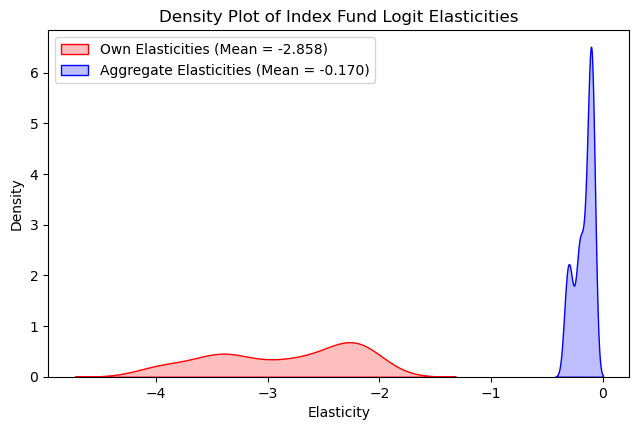

In [9]:
# compute elasticities, diversion ratio
logit_elasticities = logit_results.compute_elasticities()
logit_diversions = logit_results.compute_diversion_ratios()
logit_means = logit_results.extract_diagonal_means(logit_elasticities)
logit_aggregates = logit_results.compute_aggregate_elasticities(factor=0.1)

mean_own = logit_means.flatten().mean()
mean_agg = logit_aggregates.flatten().mean()

import matplotlib.pyplot as plt
import seaborn as sns

# Set the figure size if needed
plt.figure(figsize=(10*0.75, 6*0.75))

# Plot the density (KDE)
sns.kdeplot(logit_means.flatten(), color='red', fill=True, label=f"Own Elasticities (Mean = {mean_own:.3f})")
sns.kdeplot(logit_aggregates.flatten(), color='blue', fill=True, label=f"Aggregate Elasticities (Mean = {mean_agg:.3f})")

# Formatting
plt.legend()
plt.xlabel("Elasticity")
plt.ylabel("Density")
plt.title("Density Plot of Index Fund Logit Elasticities")

# Save and show
plt.savefig("./logit_lasticities_density_Index.pdf", format="pdf", bbox_inches="tight")
plt.show()


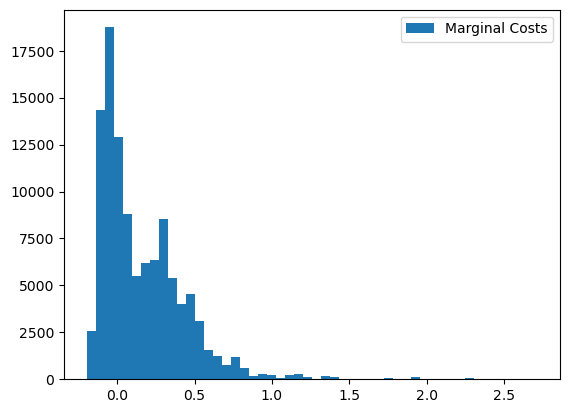

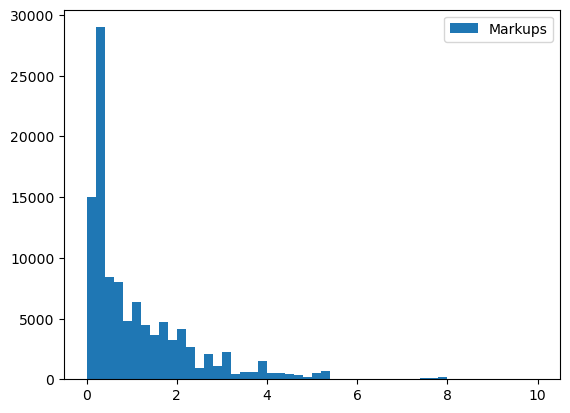

array([[1.01669414],
       [1.01669453],
       [1.01669601],
       ...,
       [0.0019773 ],
       [0.07670257],
       [0.06405718]], shape=(108300, 1))

array([[0.11591814],
       [0.1159178 ],
       [0.11591651],
       ...,
       [0.98587646],
       [0.63474969],
       [0.70883102]], shape=(108300, 1))

count    108300.000000
mean          0.157482
std           0.274116
min          -0.197220
25%          -0.051229
50%           0.069204
75%           0.315389
max           2.716706
dtype: float64

count    108300.000000
mean          1.180066
std           1.478732
min           0.038567
25%           0.267402
50%           0.635605
75%           1.658769
max          16.218533
dtype: float64

In [10]:
# compute costs and markups

costs = logit_results.compute_costs()
plt.hist(costs, bins=50);
plt.legend(["Marginal Costs"]);
plt.savefig("./logit_marginalcost_hist.pdf", format="pdf", bbox_inches="tight")
plt.show()

markups = logit_results.compute_markups(costs=costs)
plt.hist(markups, bins=50, range=(0,10));
plt.legend(["Markups"]);
plt.savefig("./logit_markups_hist.pdf", format="pdf", bbox_inches="tight")
plt.show()

display(costs)
display(markups)

display(pd.Series(costs.ravel()).describe())
display(pd.Series(markups.ravel()).describe())


In [11]:
# For BLP we need more instruments
#  19  BLP_IV_implied_swap_rate                            26937 non-null  float64
#  20  BLP_IV_implied_fund_swap_rate                       26704 non-null  float64
#  21  BLP_IV_delta_vix                                    26937 non-null  float64
#  22  BLP_IV_ICR                                          26553 non-null  float64
#  23  BLP_IV_ICR_ret                                      26937 non-null  float64
#  24  BLP_IV_hausman_exp_ratio                            26937 non-null  float64
#  25  BLP_IV_hausman_op_cost                              26937 non-null  float64
#  26  BLP_IV_hausman_mgmt_fee                             26937 non-null  float64
#  27  BLP_IV_waldfan_exp_ratio                            26937 non-null  float64
#  28  BLP_IV_waldfan_op_cost                              26937 non-null  float64
#  29  BLP_IV_waldfan_mgmt_fee                             26937 non-null  float64
#  30  BLP_IV_rival_funds1                                 26937 non-null  int64  
#  31  BLP_IV_rival_funds2                                 26937 non-null  int64  
#  32  BLP_IV_rival_funds3                                 26937 non-null  int64  
#  33  BLP_IV_rival_funds4                                 26937 non-null  int64  
#  34  BLP_IV_rival_funds5                                 26937 non-null  int64  
#  35  BLP_IV_rival_funds6                                 26937 non-null  int64  
#  36  BLP_IV_newproduct_1                                 26937 non-null  int64  
#  37  BLP_IV_newp_exp_ratio_1                             26937 non-null  float64
#  38  BLP_IV_newp_op_cost_1                               26937 non-null  float64
#  39  BLP_IV_newp_mgmt_fee_1                              26937 non-null  float64
#  40  BLP_IV_newproduct_2                                 26937 non-null  int64  
#  41  BLP_IV_newp_exp_ratio_2                             26937 non-null  float64
#  42  BLP_IV_newp_op_cost_2                               26937 non-null  float64
#  43  BLP_IV_newp_mgmt_fee_2                              2035 non-null   float64
#  44  BLP_IV_newproduct_3                                 26937 non-null  int64  
#  45  BLP_IV_newp_exp_ratio_3                             26937 non-null  float64
#  46  BLP_IV_newp_op_cost_3                               26937 non-null  float64
#  47  BLP_IV_newp_mgmt_fee_3                              1447 non-null   float64

product_data["BLP_IV_newproduct_1_x_broad"] = (
    product_data["BLP_IV_newproduct_1"] * product_data["broad_specialized_ind"]
)

product_data = product_data.rename(columns={
    # This is too correlated with BLP_IV_hausman_exp_ratio (renamed as demand_instruments1 above for logit estimation)
    #'BLP_IV_hausman_op_cost': 'demand_instruments1',
    # This one seems to work since it has some nice independent variation
    'BLP_IV_newproduct_1': 'demand_instruments2',
    'BLP_IV_newproduct_1_x_broad': 'demand_instruments3'
    # This 
    #'BLP_IV_rival_funds4': 'demand_instruments2'
})

# Prepare BLP 
X1_formulation = pyblp.Formulation('0 + prices + I(prices*broad_specialized_ind) + product_tracking_err + product_past_1yr_ret + log_product_fund_age', absorb='C(product_ids) + C(market_ids)')  
X2_formulation = pyblp.Formulation('0 + prices + I(prices*broad_specialized_ind)')
product_formulations = (X1_formulation, X2_formulation)
product_formulations

(prices + I(prices * broad_specialized_ind) + product_tracking_err + product_past_1yr_ret + log_product_fund_age + Absorb[C(product_ids)] + Absorb[C(market_ids)],
 prices + I(prices * broad_specialized_ind))

In [12]:
mc_integration = pyblp.Integration('monte_carlo', size=3000, specification_options={'seed': 623543})
mc_integration

Configured to construct nodes and weights with Monte Carlo simulation with options {seed: 623543}.

In [13]:
mc_problem = pyblp.Problem(product_formulations, product_data, integration=mc_integration)
mc_problem

Dimensions:
 T     N      F     I      K1    K2    MD    ED 
---  ------  ---  ------  ----  ----  ----  ----
166  108300  90   498000   5     2     7     2  

Formulations:
       Column Indices:           0                  1                         2                     3                     4          
-----------------------------  ------  ----------------------------  --------------------  --------------------  --------------------
 X1: Linear Characteristics    prices  broad_specialized_ind*prices  product_tracking_err  product_past_1yr_ret  log_product_fund_age
X2: Nonlinear Characteristics  prices  broad_specialized_ind*prices                                                                  

In [14]:
bfgs = pyblp.Optimization('bfgs', {'gtol': 1e-7})
bfgs

Configured to optimize using the BFGS algorithm implemented in SciPy with analytic gradients and options {gtol: +1.0000E-07}.

In [15]:
# Solve BLP
results = mc_problem.solve(np.identity(2), optimization=bfgs)
results

Problem Results Summary:
GMM    Objective    Gradient        Hessian         Hessian     Clipped  Weighting Matrix  Covariance Matrix
Step     Value        Norm      Min Eigenvalue  Max Eigenvalue  Shares   Condition Number  Condition Number 
----  -----------  -----------  --------------  --------------  -------  ----------------  -----------------
 2    +8.7529E-01  +1.5392E-08   +3.0704E-01     +7.4722E-01       0       +1.7541E+06        +1.5998E+16   

Cumulative Statistics:
Computation  Optimizer  Optimization   Objective   Fixed Point  Contraction
   Time      Converged   Iterations   Evaluations  Iterations   Evaluations
-----------  ---------  ------------  -----------  -----------  -----------
 05:00:44       Yes          15           23         165826       501907   

Nonlinear Coefficient Estimates (Robust SEs in Parentheses):
           Sigma:                prices      broad_specialized_ind*prices
----------------------------  -------------  ----------------------------
 

In [16]:
# compute elasticities, diversion ratio, costs, and markups
elasticities = results.compute_elasticities()
diversions = results.compute_diversion_ratios()
costs = results.compute_costs()
markups = results.compute_markups(costs=costs)

In [17]:
means = results.extract_diagonal_means(elasticities)
aggregates = results.compute_aggregate_elasticities(factor=0.1)

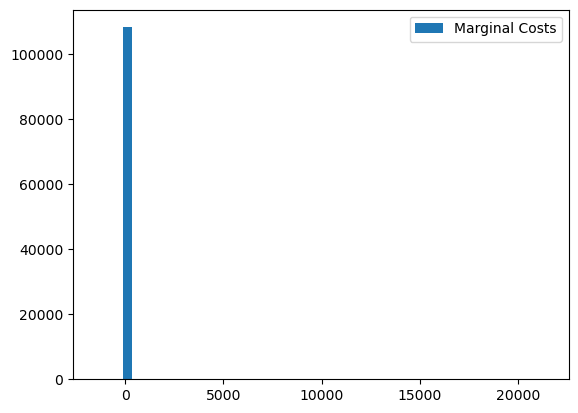

In [18]:
costs = results.compute_costs()
plt.hist(costs, bins=50);
plt.legend(["Marginal Costs"]);
plt.savefig("./marginalcost_hist.pdf", format="pdf", bbox_inches="tight")
plt.show()

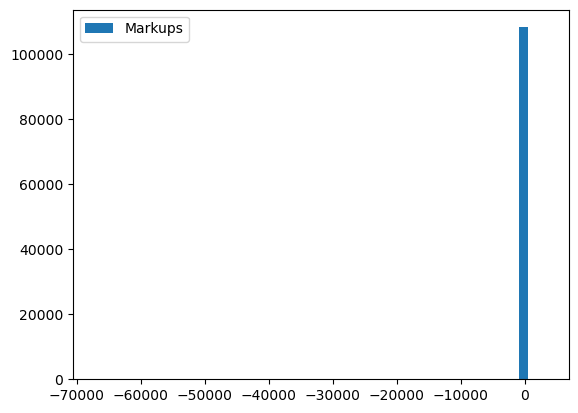

In [19]:
markups = results.compute_markups(costs=costs)
plt.hist(markups, bins=50);
plt.legend(["Markups"]);
plt.savefig("./markups_hist.pdf", format="pdf", bbox_inches="tight")
plt.show()

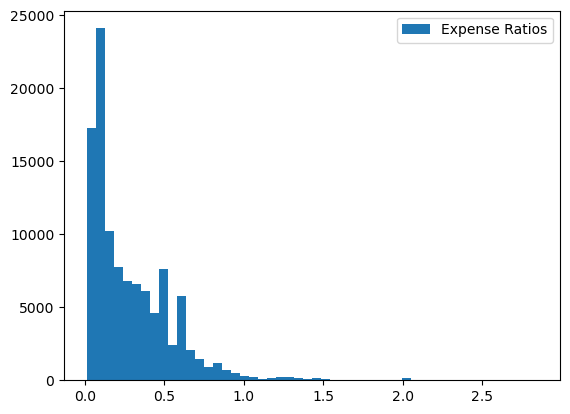

In [20]:
prices = product_data["prices"]
plt.hist(prices, bins=50);
plt.legend(["Expense Ratios"]);
plt.savefig("./expenseratio_hist.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [21]:
# 0. Extract beta estimates from PyBLP results
beta = results.beta.flatten()
beta_se = results.beta_se.flatten()
beta_names = list(results.beta_labels)

beta_df = pd.DataFrame({
    "Variable": beta_names, "Coef": beta, "SE": beta_se
})

display(beta_df)


,Variable,Coef,SE
0,prices,-32.525849,3.696575
1,broad_specialized_ind*prices,10.840671,2.300040
2,product_tracking_err,-1.892108,0.278930
3,product_past_1yr_ret,0.433358,0.031134
4,log_product_fund_age,0.559492,0.022732


In [22]:
# For BLP with more RCs, we need more instruments
#  19  BLP_IV_implied_swap_rate                            26937 non-null  float64
#  20  BLP_IV_implied_fund_swap_rate                       26704 non-null  float64
#  21  BLP_IV_delta_vix                                    26937 non-null  float64
#  22  BLP_IV_ICR                                          26553 non-null  float64
#  23  BLP_IV_ICR_ret                                      26937 non-null  float64
#  24  BLP_IV_hausman_exp_ratio                            26937 non-null  float64
#  25  BLP_IV_hausman_op_cost                              26937 non-null  float64
#  26  BLP_IV_hausman_mgmt_fee                             26937 non-null  float64
#  27  BLP_IV_waldfan_exp_ratio                            26937 non-null  float64
#  28  BLP_IV_waldfan_op_cost                              26937 non-null  float64
#  29  BLP_IV_waldfan_mgmt_fee                             26937 non-null  float64
#  30  BLP_IV_rival_funds1                                 26937 non-null  int64  
#  31  BLP_IV_rival_funds2                                 26937 non-null  int64  
#  32  BLP_IV_rival_funds3                                 26937 non-null  int64  
#  33  BLP_IV_rival_funds4                                 26937 non-null  int64  
#  34  BLP_IV_rival_funds5                                 26937 non-null  int64  
#  35  BLP_IV_rival_funds6                                 26937 non-null  int64  
#  36  BLP_IV_newproduct_1                                 26937 non-null  int64  
#  37  BLP_IV_newp_exp_ratio_1                             26937 non-null  float64
#  38  BLP_IV_newp_op_cost_1                               26937 non-null  float64
#  39  BLP_IV_newp_mgmt_fee_1                              26937 non-null  float64
#  40  BLP_IV_newproduct_2                                 26937 non-null  int64  
#  41  BLP_IV_newp_exp_ratio_2                             26937 non-null  float64
#  42  BLP_IV_newp_op_cost_2                               26937 non-null  float64
#  43  BLP_IV_newp_mgmt_fee_2                              2035 non-null   float64
#  44  BLP_IV_newproduct_3                                 26937 non-null  int64  
#  45  BLP_IV_newp_exp_ratio_3                             26937 non-null  float64
#  46  BLP_IV_newp_op_cost_3                               26937 non-null  float64
#  47  BLP_IV_newp_mgmt_fee_3                              1447 non-null   float64

product_data["log_BLP_IV_rival_log_fund_age4"] = np.log(product_data["BLP_IV_rival_log_fund_age4"])
product_data["log_BLP_IV_rival_tracking_err4"] = np.log(product_data["BLP_IV_rival_tracking_err4"])

product_data = product_data.rename(columns={
    'log_BLP_IV_rival_log_fund_age4': 'demand_instruments4'
})

product_data = product_data.rename(columns={
    'log_BLP_IV_rival_tracking_err4': 'demand_instruments5'
})

In [23]:
# Prepare BLP with additional RCs V2
X1_formulation = pyblp.Formulation('0 + prices + I(prices*broad_specialized_ind) + product_tracking_err + product_past_1yr_ret + log_product_fund_age', absorb='C(product_ids) + C(market_ids)')  
X2_formulation = pyblp.Formulation('0 + prices + I(prices*broad_specialized_ind) + log_product_fund_age + product_past_1yr_ret')
product_formulations = (X1_formulation, X2_formulation)
product_formulations

mc_integration = pyblp.Integration('monte_carlo', size=3000, specification_options={'seed': 623543})
mc_integration

mc_problem = pyblp.Problem(product_formulations, product_data, integration=mc_integration)
mc_problem

bfgs = pyblp.Optimization('bfgs', {'gtol': 1e-7})
bfgs

# Solve BLP
results_v3 = mc_problem.solve(np.identity(4), optimization=bfgs)
results_v3

Problem Results Summary:
GMM    Objective    Gradient        Hessian         Hessian     Clipped  Weighting Matrix  Covariance Matrix
Step     Value        Norm      Min Eigenvalue  Max Eigenvalue  Shares   Condition Number  Condition Number 
----  -----------  -----------  --------------  --------------  -------  ----------------  -----------------
 2    +1.0056E+02  +9.3568E-07   +3.5749E+00     +2.2924E+02       0       +1.8873E+06        +9.4956E+15   

Cumulative Statistics:
Computation  Optimizer  Optimization   Objective   Fixed Point  Contraction
   Time      Converged   Iterations   Evaluations  Iterations   Evaluations
-----------  ---------  ------------  -----------  -----------  -----------
 05:05:10       No           22           87         142958       441795   

Nonlinear Coefficient Estimates (Robust SEs in Parentheses):
           Sigma:                prices      broad_specialized_ind*prices  log_product_fund_age  product_past_1yr_ret
----------------------------  -

In [24]:
# compute elasticities, diversion ratio, costs, and markups for RC v3
elasticities = results_v3.compute_elasticities()
diversions = results_v3.compute_diversion_ratios()
costs = results_v3.compute_costs()
markups = results_v3.compute_markups(costs=costs)

means = results_v3.extract_diagonal_means(elasticities)
aggregates = results_v3.compute_aggregate_elasticities(factor=0.1)

mean_own = means.flatten().mean()
mean_agg = aggregates.flatten().mean()
mean_own

np.float64(-2.799756976984169)

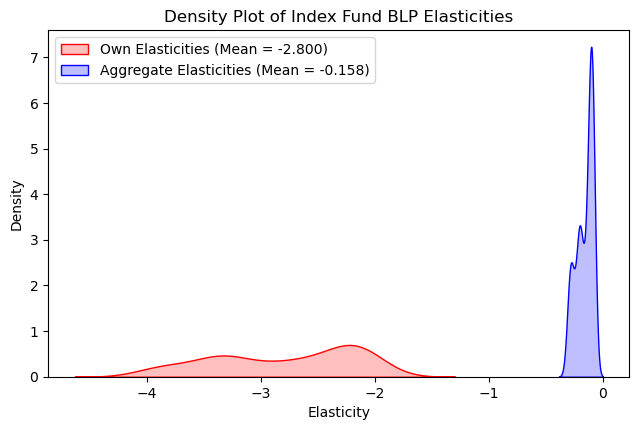

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

# Keep your mean calculations
mean_own = means.flatten().mean()
mean_agg = aggregates.flatten().mean()

# Set the figure size if needed
plt.figure(figsize=(10*0.75, 6*0.75))

# Plot the density (KDE)
sns.kdeplot(means.flatten(), color='red', fill=True, label=f"Own Elasticities (Mean = {mean_own:.3f})")
sns.kdeplot(aggregates.flatten(), color='blue', fill=True, label=f"Aggregate Elasticities (Mean = {mean_agg:.3f})")

# Formatting
plt.legend()
plt.xlabel("Elasticity")
plt.ylabel("Density")
plt.title("Density Plot of Index Fund BLP Elasticities")

# Save and show
plt.savefig("./BLP_elasticities_density_Index.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [26]:
# compute elasticities, diversion ratio
results_v3.compute_elasticities()

array([[-8.22322515e+00,  4.73383496e-04,  3.44140724e-04, ...,
                    nan,             nan,             nan],
       [-8.22325095e+00,  4.41814172e-04,  3.32593758e-04, ...,
                    nan,             nan,             nan],
       [-8.22372826e+00,  3.96229775e-04,  2.81561051e-04, ...,
                    nan,             nan,             nan],
       ...,
       [ 3.47737065e-05,  1.18885623e-03,  7.80879003e-04, ...,
                    nan,             nan,             nan],
       [ 3.45178193e-05,  1.19019053e-03,  7.81082261e-04, ...,
                    nan,             nan,             nan],
       [ 3.45178775e-05,  1.19019074e-03,  7.81082564e-04, ...,
                    nan,             nan,             nan]],
      shape=(108300, 711))

In [ ]:
import os
import pandas as pd
import numpy as np

# suppose your data frame is called df
# and it contains a column named 'market_id'
market_ids = product_data['market_ids'].dropna().unique()

# optional: sort them
market_ids = sorted(market_ids)

# folder to save outputs
output_dir = "elasticity_outputs"
os.makedirs(output_dir, exist_ok=True)

for mid in market_ids:
    try:
        # compute elasticities for this market
        elast = logit_results.compute_elasticities(market_id=mid)

        # convert to DataFrame
        elast_df = pd.DataFrame(elast)

        # save to csv
        out_file = os.path.join(output_dir, f"logit_elasticities_nonlev_market_{mid}.csv")
        elast_df.to_csv(out_file, index=False)

        print(f"Saved: {out_file}")

    except Exception as e:
        print(f"Error for market_id={mid}: {e}")

In [ ]:
import os
import pandas as pd
import numpy as np

# suppose your data frame is called df
# and it contains a column named 'market_id'
market_ids = product_data['market_ids'].dropna().unique()

# optional: sort them
market_ids = sorted(market_ids)

# folder to save outputs
output_dir = "elasticity_outputs"
os.makedirs(output_dir, exist_ok=True)

for mid in market_ids:
    try:
        # compute elasticities for this market
        elast = results_v3.compute_elasticities(market_id=mid)

        # convert to DataFrame
        elast_df = pd.DataFrame(elast)

        # save to csv
        out_file = os.path.join(output_dir, f"elasticities_nonlev_market_{mid}.csv")
        elast_df.to_csv(out_file, index=False)

        print(f"Saved: {out_file}")

    except Exception as e:
        print(f"Error for market_id={mid}: {e}")

In [27]:
import copy

def kappa_specification1(f, g):
    return (
        1 if f == g
        else 0 if {f, g} == {"BlackRock", "Vanguard"}
        else 0 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

def kappa_specification2(f, g):
    return (
        1 if f == g
        else 0.25 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.25 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.25 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

def kappa_specification3(f, g):
    return (
        1 if f == g
        else 0.5 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.5 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.5 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

def kappa_specification4(f, g):
    return (
        1 if f == g
        else 0.55 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.55 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.55 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

def kappa_specification5(f, g):
    return (
        1 if f == g
        else 0.60 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.60 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.60 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

def kappa_specification6(f, g):
    return (
        1 if f == g
        else 0.65 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.65 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.65 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )
  
def kappa_specification7(f, g):
    return (
        1 if f == g
        else 0.70 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.70 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.70 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

def kappa_specification8(f, g):
    return (
        1 if f == g
        else 0.75 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.75 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.75 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

# Version where we adjust the price to account for economies of scale:
product_data_econ_scale=copy.deepcopy(product_data)

#product_data_econ_scale['prices'] = product_data_econ_scale['prices'] - (-0.040)*np.log(product_data_econ_scale['product_mtna'])
#product_data_econ_scale['index_product_mtna'] = product_data_econ_scale.groupby('market_m_index')['product_mtna'].transform('sum')
#product_data_econ_scale['prices'] = product_data_econ_scale['prices'] - (-0.116)*np.log(product_data_econ_scale['index_product_mtna'])

#product_data_econ_scale['log_product_mtna'] = np.log(product_data_econ_scale['product_mtna'])

# Now set up problem for conduct testing
testing_problem = pyRVtest.Problem(
    cost_formulation = (
        pyRVtest.Formulation('0 + log_product_fund_age + product_tracking_err + product_past_1yr_ret', absorb = 'C(product_ids) + C(market_ids)' )
    ),
    instrument_formulation = (
        # Neg works better than abs as we expect
        #pyRVtest.Formulation('0 + Conduct_IV_abs_vw_ind_resid_1m + Conduct_IV_abs_vw_ind_resid_2to5m + Conduct_IV_abs_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + Conduct_IV_neg_vw_ind_resid_1m + Conduct_IV_neg_vw_ind_resid_2to5m + Conduct_IV_neg_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + demand_instruments0 + IV_x_neg_vw_ind_resid_1m + IV_x_neg_vw_ind_resid_2to5m + IV_x_neg_vw_ind_resid_6to12m')        
        pyRVtest.Formulation('0 + BLP_IV_rival_funds2*Conduct_IV_csent_index_resid')      

### These interactions reject PC and support ProShares + Direxion
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_index_resid
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_age1
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_age3
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_income1_resid
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_income3_resid
# This works: BLP_IV_rival_funds3*Conduct_IV_csent_index_resid

### These interactions reject PC and support ProShares + ProFunds
# This works: BLP_IV_rival_funds2*Conduct_IV_vol_resid1

        #  List of candidate instruments
#  77  Conduct_IV_gs_leveraged_etf_resid           26937 non-null  float64
#  78  Conduct_IV_gs_bitcoin_resid        26937 non-null  float64
#  79  Conduct_IV_csent_index_resid       26937 non-null  float64
#  80  Conduct_IV_vol_resid1           26937 non-null  float64
#  80  BLP_IV_waldfan_exp_ratio           26937 non-null  float64

    ),
    model_formulations = (
        pyRVtest.ModelFormulation(model_downstream='perfect_competition', ownership_downstream='firm_ids'),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids'),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification1),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification2),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification3),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification4),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification5),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification6),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification7),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification8),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification10)
        pyRVtest.ModelFormulation(model_downstream='cournot', ownership_downstream='firm_ids'),
        pyRVtest.ModelFormulation(model_downstream='monopoly', ownership_downstream='firm_ids')
    ),
    product_data = product_data_econ_scale,
    demand_results = results_v3
)
testing_problem

Dimensions:
 T     N      M    L   d_z0
---  ------  ---  ---  ----
166  108300  11    1    3  

Formulations:
Column Indices:            0                         1                                       2                        
----------------  --------------------  ----------------------------  ------------------------------------------------
w: Marginal Cost  log_product_fund_age      product_tracking_err                    product_past_1yr_ret              
z0: Instruments   BLP_IV_rival_funds2   Conduct_IV_csent_index_resid  BLP_IV_rival_funds2*Conduct_IV_csent_index_resid

Models:
                                0              1         2         3         4         5         6         7         8         9         10   
---------------------  -------------------  --------  --------  --------  --------  --------  --------  --------  --------  --------  --------
 Model - Downstream    perfect_competition  bertrand  bertrand  bertrand  bertrand  bertrand  bertrand  bertrand  bert

In [28]:
testing_results = testing_problem.solve(
    demand_adjustment=False,    
    clustering_adjustment=True
)
testing_results

Computing Markups ... 
Total Time is ... 376.92249035835266




Testing Results - Instruments z0:
  TRV:                                                                                         |   F-stats:                                                                                                  |    MCS:                
--------  ---  ------  ------  ------  ------  ------  ------  ------  ------  ------  ------  |  ----------  ---  -------  -------  -------  -------  -------  -------  -------  -------  -------  -------  |  --------  ------------
 models    0     1       2       3       4       5       6       7       8       9       10    |    models     0      1        2        3        4        5        6        7        8        9       10     |   models   MCS p-values
--------  ---  ------  ------  ------  ------  ------  ------  ------  ------  ------  ------  |  ----------  ---  -------  -------  -------  -------  -------  -------  -------  -------  -------  -------  |  --------  ------------
   0      nan  -2.631  -0.992  -0.399  -

In [29]:
# Save the level markup, level marginal cost, and lerner index data into the df
product_data['BLP_mu_pc'] = testing_results.markups[0]
product_data['BLP_mu_bt'] = testing_results.markups[1]
product_data['BLP_mu_bt_big3_025'] = testing_results.markups[2]
product_data['BLP_mu_bt_big3_050'] = testing_results.markups[3]
product_data['BLP_mu_bt_big3_055'] = testing_results.markups[4]
product_data['BLP_mu_bt_big3_060'] = testing_results.markups[5]
product_data['BLP_mu_bt_big3_065'] = testing_results.markups[6]
product_data['BLP_mu_bt_big3_070'] = testing_results.markups[7]
product_data['BLP_mu_bt_big3_075'] = testing_results.markups[8]
product_data['BLP_mu_cournot'] = testing_results.markups[9]
product_data['BLP_mu_monopoly'] = testing_results.markups[10]

product_data['BLP_mc_pc'] = testing_results.marginal_cost[0]
product_data['BLP_mc_bt'] = testing_results.marginal_cost[1]
product_data['BLP_mc_bt_big3_025'] = testing_results.marginal_cost[2]
product_data['BLP_mc_bt_big3_050'] = testing_results.marginal_cost[3]
product_data['BLP_mc_bt_big3_055'] = testing_results.marginal_cost[4]
product_data['BLP_mc_bt_big3_060'] = testing_results.marginal_cost[5]
product_data['BLP_mc_bt_big3_065'] = testing_results.marginal_cost[6]
product_data['BLP_mc_bt_big3_070'] = testing_results.marginal_cost[7]
product_data['BLP_mc_bt_big3_075'] = testing_results.marginal_cost[8]
product_data['BLP_mc_cournot'] = testing_results.marginal_cost[9]
product_data['BLP_mc_monopoly'] = testing_results.marginal_cost[10]

product_data['BLP_lerner_pc'] = product_data['BLP_mu_pc']/product_data['prices']
product_data['BLP_lerner_bt'] = product_data['BLP_mu_bt']/product_data['prices']
product_data['BLP_lerner_bt_big3_025'] = product_data['BLP_mu_bt_big3_025']/product_data['prices']
product_data['BLP_lerner_bt_big3_050'] = product_data['BLP_mu_bt_big3_050']/product_data['prices']
product_data['BLP_lerner_bt_big3_055'] = product_data['BLP_mu_bt_big3_055']/product_data['prices']
product_data['BLP_lerner_bt_big3_060'] = product_data['BLP_mu_bt_big3_060']/product_data['prices']
product_data['BLP_lerner_bt_big3_065'] = product_data['BLP_mu_bt_big3_065']/product_data['prices']
product_data['BLP_lerner_bt_big3_070'] = product_data['BLP_mu_bt_big3_070']/product_data['prices']
product_data['BLP_lerner_bt_big3_075'] = product_data['BLP_mu_bt_big3_075']/product_data['prices']
product_data['BLP_lerner_cournot'] = product_data['BLP_mu_cournot']/product_data['prices']
product_data['BLP_lerner_monopoly'] = product_data['BLP_mu_monopoly']/product_data['prices']

print(np.mean(product_data['BLP_lerner_pc']>1))
print(np.mean(product_data['BLP_lerner_bt']>1))
print(np.mean(product_data['BLP_lerner_bt_big3_025']>1))
print(np.mean(product_data['BLP_lerner_bt_big3_050']>1))
print(np.mean(product_data['BLP_lerner_bt_big3_055']>1))
print(np.mean(product_data['BLP_lerner_bt_big3_060']>1))
print(np.mean(product_data['BLP_lerner_bt_big3_065']>1))
print(np.mean(product_data['BLP_lerner_bt_big3_070']>1))
print(np.mean(product_data['BLP_lerner_bt_big3_075']>1))
print(np.mean(product_data['BLP_lerner_cournot']>1))
print(np.mean(product_data['BLP_lerner_monopoly']>1))

0.0
0.3994921514312096
0.4349399815327793
0.46128347183748847
0.46505078485687906
0.469353647276085
0.4721791320406279
0.47578947368421054
0.4857433056325023
0.5032225300092336
0.954118190212373


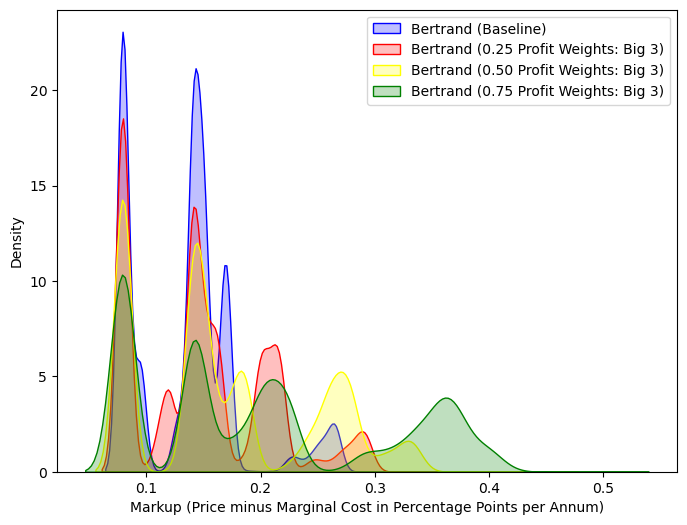

In [30]:
import seaborn as sns

plt.figure(figsize=(8, 6)) # Optional: control figure size

# Plot the first density curve
sns.kdeplot(x=testing_results.markups[1].ravel(), label='Bertrand (Baseline)', color='blue', fill=True, alpha=0.25)
sns.kdeplot(x=testing_results.markups[2].ravel(), label='Bertrand (0.25 Profit Weights: Big 3)', color='red', fill=True, alpha=0.25)
sns.kdeplot(x=testing_results.markups[3].ravel(), label='Bertrand (0.50 Profit Weights: Big 3)', color='yellow', fill=True, alpha=0.25)
sns.kdeplot(x=testing_results.markups[8].ravel(), label='Bertrand (0.75 Profit Weights: Big 3)', color='green', fill=True, alpha=0.25)

#plt.xlim(0, 2)
#plt.ylim(0, 6)
plt.xlabel('Markup (Price minus Marginal Cost in Percentage Points per Annum)')
plt.ylabel('Density')
plt.legend() # Show the legend with the labels

plt.savefig("./Index Bertrand and Partial Collusion.pdf", format="pdf", bbox_inches="tight")
plt.show()

#plt.savefig("./Bertrand and Partial Collusion Combos.pdf", format="pdf", bbox_inches="tight")
#plt.show()

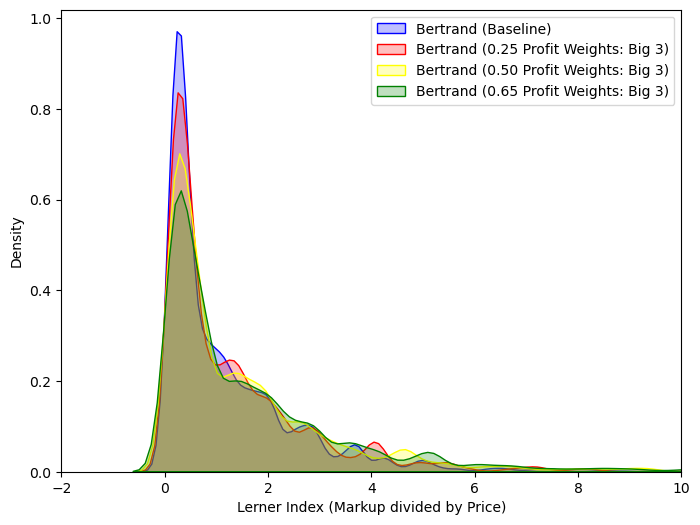

In [31]:
import seaborn as sns

plt.figure(figsize=(8, 6)) # Optional: control figure size

# Plot the first density curve
sns.kdeplot(x=product_data['BLP_lerner_bt'], label='Bertrand (Baseline)', color='blue', fill=True, alpha=0.25)
sns.kdeplot(x=product_data['BLP_lerner_bt_big3_025'], label='Bertrand (0.25 Profit Weights: Big 3)', color='red', fill=True, alpha=0.25)
sns.kdeplot(x=product_data['BLP_lerner_bt_big3_050'], label='Bertrand (0.50 Profit Weights: Big 3)', color='yellow', fill=True, alpha=0.25)
sns.kdeplot(x=product_data['BLP_lerner_bt_big3_065'], label='Bertrand (0.65 Profit Weights: Big 3)', color='green', fill=True, alpha=0.25)

plt.xlim(-2, 10)
#plt.ylim(0, 6)
plt.xlabel('Lerner Index (Markup divided by Price)')
plt.ylabel('Density')
plt.legend() # Show the legend with the labels

plt.savefig("./Index Lerner Bertrand and Partial Collusion.pdf", format="pdf", bbox_inches="tight")
plt.show()

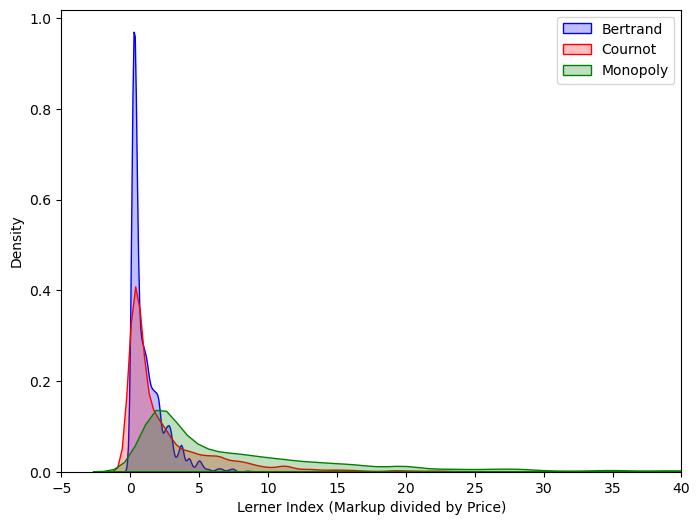

In [32]:
import seaborn as sns

plt.figure(figsize=(8, 6)) # Optional: control figure size

# Plot the first density curve
sns.kdeplot(x=product_data['BLP_lerner_bt'], label='Bertrand', color='blue', fill=True, alpha=0.25)
sns.kdeplot(x=product_data['BLP_lerner_cournot'], label='Cournot', color='red', fill=True, alpha=0.25)
sns.kdeplot(x=product_data['BLP_lerner_monopoly'], label='Monopoly', color='green', fill=True, alpha=0.25)

plt.xlim(-5, 40)
#plt.ylim(0, 6)
plt.xlabel('Lerner Index (Markup divided by Price)')
plt.ylabel('Density')
plt.legend() # Show the legend with the labels

plt.savefig("./Index Lerner Cournot_Monopoly.pdf", format="pdf", bbox_inches="tight")
plt.show()

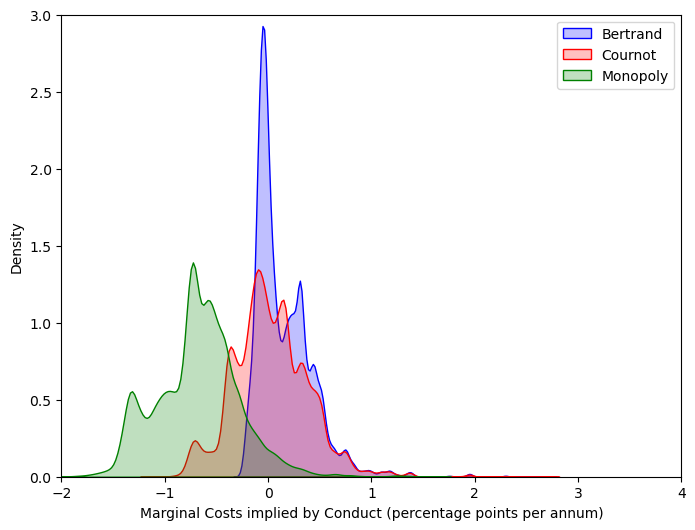

In [33]:
import seaborn as sns

plt.figure(figsize=(8, 6)) # Optional: control figure size

# Plot the first density curve
sns.kdeplot(x=product_data['BLP_mc_bt'], label='Bertrand', color='blue', fill=True, alpha=0.25)
sns.kdeplot(x=product_data['BLP_mc_cournot'], label='Cournot', color='red', fill=True, alpha=0.25)
sns.kdeplot(x=product_data['BLP_mc_monopoly'], label='Monopoly', color='green', fill=True, alpha=0.25)

plt.xlim(-2, 4)
plt.ylim(0, 3)
plt.xlabel('Marginal Costs implied by Conduct (percentage points per annum)')
plt.ylabel('Density')
plt.legend() # Show the legend with the labels

plt.savefig("./Index MC Cournot_Monopoly.pdf", format="pdf", bbox_inches="tight")
plt.show()

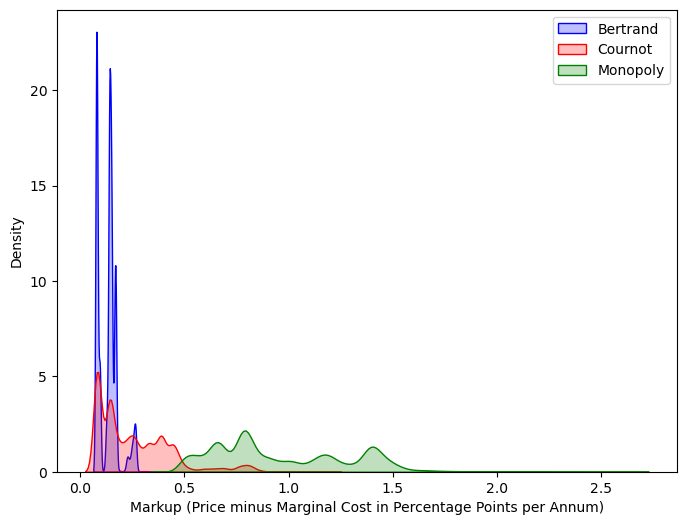

In [34]:
import seaborn as sns

plt.figure(figsize=(8, 6)) # Optional: control figure size

# Plot the first density curve
sns.kdeplot(x=testing_results.markups[1].ravel(), label='Bertrand', color='blue', fill=True, alpha=0.25)
sns.kdeplot(x=testing_results.markups[9].ravel(), label='Cournot', color='red', fill=True, alpha=0.25)
sns.kdeplot(x=testing_results.markups[10].ravel(), label='Monopoly', color='green', fill=True, alpha=0.25)

#plt.xlim(0, 1)
#plt.ylim(0, 6)
plt.xlabel('Markup (Price minus Marginal Cost in Percentage Points per Annum)')
plt.ylabel('Density')
plt.legend() # Show the legend with the labels

plt.savefig("./Index Cournot_Monopoly.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [35]:
# Save implied marginal costs
product_data.to_csv("nonlev_product_data_w_costs_Mar2025_matchEgan.csv", index=False)
#product_data.to_csv("nonlev_product_data_w_costs_Mar2025_matchEgan_BLP1RC.csv", index=False)

In [ ]:
import copy

def kappa_specification1(f, g):
    return (
        1 if f == g
        else 0 if {f, g} == {"BlackRock", "Vanguard"}
        else 0 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

def kappa_specification2(f, g):
    return (
        1 if f == g
        else 0.25 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.25 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.25 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

def kappa_specification3(f, g):
    return (
        1 if f == g
        else 0.5 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.5 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.5 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

def kappa_specification4(f, g):
    return (
        1 if f == g
        else 0.55 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.55 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.55 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

def kappa_specification5(f, g):
    return (
        1 if f == g
        else 0.60 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.60 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.60 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

def kappa_specification6(f, g):
    return (
        1 if f == g
        else 0.65 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.65 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.65 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )
  
def kappa_specification7(f, g):
    return (
        1 if f == g
        else 0.70 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.70 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.70 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

def kappa_specification8(f, g):
    return (
        1 if f == g
        else 0.75 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.75 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.75 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )


# Version where we adjust the price to account for economies of scale:
product_data_econ_scale=copy.deepcopy(product_data)

product_data_econ_scale['prices'] = product_data_econ_scale['prices'] - (-0.024)*np.log(product_data_econ_scale['product_mtna'])
#product_data_econ_scale['index_product_mtna'] = product_data_econ_scale.groupby('market_m_index')['product_mtna'].transform('sum')
#product_data_econ_scale['prices'] = product_data_econ_scale['prices'] - (-0.116)*np.log(product_data_econ_scale['index_product_mtna'])

#product_data_econ_scale['log_product_mtna'] = np.log(product_data_econ_scale['product_mtna'])

# Now set up problem for conduct testing
testing_problem = pyRVtest.Problem(
    cost_formulation = (
        pyRVtest.Formulation('0 + log_product_fund_age + product_tracking_err + product_past_1yr_ret', absorb = 'C(product_ids) + C(market_ids)' )
    ),
    instrument_formulation = (
        # Neg works better than abs as we expect
        #pyRVtest.Formulation('0 + Conduct_IV_abs_vw_ind_resid_1m + Conduct_IV_abs_vw_ind_resid_2to5m + Conduct_IV_abs_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + Conduct_IV_neg_vw_ind_resid_1m + Conduct_IV_neg_vw_ind_resid_2to5m + Conduct_IV_neg_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + demand_instruments0 + IV_x_neg_vw_ind_resid_1m + IV_x_neg_vw_ind_resid_2to5m + IV_x_neg_vw_ind_resid_6to12m')        
        pyRVtest.Formulation('0 + BLP_IV_rival_funds2*Conduct_IV_csent_index_resid')      

### These interactions reject PC and support ProShares + Direxion
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_index_resid
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_age1
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_age3
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_income1_resid
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_income3_resid
# This works: BLP_IV_rival_funds3*Conduct_IV_csent_index_resid

### These interactions reject PC and support ProShares + ProFunds
# This works: BLP_IV_rival_funds2*Conduct_IV_vol_resid1

        #  List of candidate instruments
#  77  Conduct_IV_gs_leveraged_etf_resid           26937 non-null  float64
#  78  Conduct_IV_gs_bitcoin_resid        26937 non-null  float64
#  79  Conduct_IV_csent_index_resid       26937 non-null  float64
#  80  Conduct_IV_vol_resid1           26937 non-null  float64
#  80  BLP_IV_waldfan_exp_ratio           26937 non-null  float64

    ),
    model_formulations = (
        pyRVtest.ModelFormulation(model_downstream='perfect_competition', ownership_downstream='firm_ids'),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids'),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification1),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification2),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification3),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification4),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification5),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification6),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification7),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification8),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification10)
        #pyRVtest.ModelFormulation(model_downstream='cournot', ownership_downstream='firm_ids'),
        #pyRVtest.ModelFormulation(model_downstream='monopoly', ownership_downstream='firm_ids')
    ),
    product_data = product_data_econ_scale,
    demand_results = results_v3
)
testing_problem

testing_results = testing_problem.solve(
    demand_adjustment=False,    
    clustering_adjustment=True
)
testing_results

In [ ]:
# Version where we adjust the price to account for economies of scale:
product_data_econ_scale=copy.deepcopy(product_data)

product_data_econ_scale['prices'] = product_data_econ_scale['prices'] - (-0.024)*np.log(product_data_econ_scale['product_mtna'])
#product_data_econ_scale['index_product_mtna'] = product_data_econ_scale.groupby('market_m_index')['product_mtna'].transform('sum')
#product_data_econ_scale['prices'] = product_data_econ_scale['prices'] - (-0.116)*np.log(product_data_econ_scale['index_product_mtna'])

#product_data_econ_scale['log_product_mtna'] = np.log(product_data_econ_scale['product_mtna'])

# Now set up problem for conduct testing
testing_problem = pyRVtest.Problem(
    cost_formulation = (
        pyRVtest.Formulation('0 + log_product_fund_age + product_tracking_err + product_past_1yr_ret', absorb = 'C(product_ids) + C(market_ids)' )
    ),
    instrument_formulation = (
        # Neg works better than abs as we expect
        #pyRVtest.Formulation('0 + Conduct_IV_abs_vw_ind_resid_1m + Conduct_IV_abs_vw_ind_resid_2to5m + Conduct_IV_abs_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + Conduct_IV_neg_vw_ind_resid_1m + Conduct_IV_neg_vw_ind_resid_2to5m + Conduct_IV_neg_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + demand_instruments0 + IV_x_neg_vw_ind_resid_1m + IV_x_neg_vw_ind_resid_2to5m + IV_x_neg_vw_ind_resid_6to12m')        
        pyRVtest.Formulation('0 + BLP_IV_rival_funds2 + BLP_IV_rival_funds2:Conduct_IV_csent_index_resid + Conduct_IV_csent_index_resid')      

### These interactions support PC
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_index_resid
# This works: BLP_IV_rival_funds2*Conduct_IV_bab_usa_resid
# This works: BLP_IV_rival_funds2*Conduct_IV_fmax_resid
# This works: BLP_IV_rival_funds2*rotator
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_income3_resid
# This works: BLP_IV_rival_funds3*Conduct_IV_csent_index_resid

### These interactions reject PC and support ProShares + ProFunds
# This works: BLP_IV_rival_funds2*Conduct_IV_vol_resid1

        #  List of candidate instruments
#  77  Conduct_IV_gs_leveraged_etf_resid           26937 non-null  float64
#  78  Conduct_IV_gs_bitcoin_resid        26937 non-null  float64
#  79  Conduct_IV_csent_index_resid       26937 non-null  float64
#  80  Conduct_IV_vol_resid1           26937 non-null  float64
#  80  BLP_IV_waldfan_exp_ratio           26937 non-null  float64

    ),
    model_formulations = (
        pyRVtest.ModelFormulation(model_downstream='perfect_competition', ownership_downstream='firm_ids'),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids'),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification1),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification2),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification3),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification4),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification5),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification6),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification7),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification8),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification10)
        #pyRVtest.ModelFormulation(model_downstream='cournot', ownership_downstream='firm_ids'),
        #pyRVtest.ModelFormulation(model_downstream='monopoly', ownership_downstream='firm_ids')
    ),
    product_data = product_data_econ_scale,
    demand_results = results_v3
)
testing_problem

testing_results = testing_problem.solve(
    demand_adjustment=False,    
    clustering_adjustment=True
)
testing_results

In [ ]:
testing_results.markups[0][product_data['month_t'] > (2020+9/12)] = 0
testing_results.markups[1][product_data['month_t'] > (2020+9/12)] = 0
testing_results.markups[2][product_data['month_t'] > (2020+9/12)] = 0
testing_results.markups[3][product_data['month_t'] > (2020+9/12)] = 0
testing_results.markups[4][product_data['month_t'] > (2020+9/12)] = 0

product_data_econ_scale_post=copy.deepcopy(product_data_econ_scale)

product_data_econ_scale_post['perfect_competition_pre'] = testing_results.markups[0]
product_data_econ_scale_post['bertrand_pre'] = testing_results.markups[1]
product_data_econ_scale_post['bt_big3_025'] = testing_results.markups[2]
product_data_econ_scale_post['bt_big3_050'] = testing_results.markups[3]
product_data_econ_scale_post['bt_big3_065'] = testing_results.markups[4]

# Now set up problem for conduct testing in sub-samples
testing_problem_post = pyRVtest.Problem(
    cost_formulation = (
        pyRVtest.Formulation('0 + log_product_fund_age + product_tracking_err + product_past_1yr_ret', absorb = 'C(product_ids) + C(market_ids)' )
    ),
    instrument_formulation = (
        # Neg works better than abs as we expect
        #pyRVtest.Formulation('0 + Conduct_IV_abs_vw_ind_resid_1m + Conduct_IV_abs_vw_ind_resid_2to5m + Conduct_IV_abs_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + Conduct_IV_neg_vw_ind_resid_1m + Conduct_IV_neg_vw_ind_resid_2to5m + Conduct_IV_neg_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + demand_instruments0 + IV_x_neg_vw_ind_resid_1m + IV_x_neg_vw_ind_resid_2to5m + IV_x_neg_vw_ind_resid_6to12m')        
        pyRVtest.Formulation('0 + BLP_IV_rival_funds2*Conduct_IV_csent_index_resid')        
        #  List of candidate instruments
#  77  Conduct_IV_abs_Conduct_IV_vw_ind_resid_1m           26937 non-null  float64
#  78  Conduct_IV_abs_Conduct_IV_vw_ind_resid_2to5m        26937 non-null  float64
#  79  Conduct_IV_abs_Conduct_IV_vw_ind_resid_6to12m       26937 non-null  float64
#  80  Conduct_IV_pos_Conduct_IV_vw_ind_resid_1m           26937 non-null  float64
#  81  Conduct_IV_pos_Conduct_IV_vw_ind_resid_2to5m        26937 non-null  float64
#  82  Conduct_IV_pos_Conduct_IV_vw_ind_resid_6to12m       26937 non-null  float64
#  83  Conduct_IV_neg_Conduct_IV_vw_ind_resid_1m           26937 non-null  float64
#  84  Conduct_IV_neg_Conduct_IV_vw_ind_resid_2to5m        26937 non-null  float64
#  85  Conduct_IV_neg_Conduct_IV_vw_ind_resid_6to12m       26937 non-null  float64


    ),
    model_formulations = (
        pyRVtest.ModelFormulation(user_supplied_markups='perfect_competition_pre'),
        pyRVtest.ModelFormulation(user_supplied_markups='bertrand_pre'),
        pyRVtest.ModelFormulation(user_supplied_markups='bt_big3_025'),
        pyRVtest.ModelFormulation(user_supplied_markups='bt_big3_050'),
        pyRVtest.ModelFormulation(user_supplied_markups='bt_big3_065')
    ),
    product_data = product_data_econ_scale_post,
    demand_results = results_v3
)
testing_problem_post

testing_results_post = testing_problem_post.solve(
    demand_adjustment=False,    
    clustering_adjustment=False
)
testing_results_post

In [ ]:
import copy

def kappa_specification1(f, g):
    return (
        1 if f == g
        else 0 if {f, g} == {"BlackRock", "Vanguard"}
        else 0 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

def kappa_specification2(f, g):
    return (
        1 if f == g
        else 0.25 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.25 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.25 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

def kappa_specification3(f, g):
    return (
        1 if f == g
        else 0.5 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.5 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.5 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

def kappa_specification4(f, g):
    return (
        1 if f == g
        else 0.55 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.55 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.55 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

def kappa_specification5(f, g):
    return (
        1 if f == g
        else 0.60 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.60 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.60 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

def kappa_specification6(f, g):
    return (
        1 if f == g
        else 0.65 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.65 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.65 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )
  
def kappa_specification7(f, g):
    return (
        1 if f == g
        else 0.70 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.70 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.70 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

def kappa_specification8(f, g):
    return (
        1 if f == g
        else 0.75 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.75 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.75 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )


# Version where we adjust the price to account for economies of scale:
product_data_econ_scale=copy.deepcopy(product_data)

product_data_econ_scale['prices'] = product_data_econ_scale['prices'] - (-0.024)*np.log(product_data_econ_scale['product_mtna'])
#product_data_econ_scale['index_product_mtna'] = product_data_econ_scale.groupby('market_m_index')['product_mtna'].transform('sum')
#product_data_econ_scale['prices'] = product_data_econ_scale['prices'] - (-0.116)*np.log(product_data_econ_scale['index_product_mtna'])

#product_data_econ_scale['log_product_mtna'] = np.log(product_data_econ_scale['product_mtna'])

# Now set up problem for conduct testing
testing_problem = pyRVtest.Problem(
    cost_formulation = (
        pyRVtest.Formulation('0 + log_product_fund_age + product_tracking_err + product_past_1yr_ret', absorb = 'C(product_ids) + C(market_ids)' )
    ),
    instrument_formulation = (
        # Neg works better than abs as we expect
        #pyRVtest.Formulation('0 + Conduct_IV_abs_vw_ind_resid_1m + Conduct_IV_abs_vw_ind_resid_2to5m + Conduct_IV_abs_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + Conduct_IV_neg_vw_ind_resid_1m + Conduct_IV_neg_vw_ind_resid_2to5m + Conduct_IV_neg_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + demand_instruments0 + IV_x_neg_vw_ind_resid_1m + IV_x_neg_vw_ind_resid_2to5m + IV_x_neg_vw_ind_resid_6to12m')        
        pyRVtest.Formulation('0 + BLP_IV_rival_funds2*Conduct_IV_csent_index_resid')      

### These interactions reject PC and support ProShares + Direxion
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_index_resid
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_age1
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_age3
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_income1_resid
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_income3_resid
# This works: BLP_IV_rival_funds3*Conduct_IV_csent_index_resid

### These interactions reject PC and support ProShares + ProFunds
# This works: BLP_IV_rival_funds2*Conduct_IV_vol_resid1

        #  List of candidate instruments
#  77  Conduct_IV_gs_leveraged_etf_resid           26937 non-null  float64
#  78  Conduct_IV_gs_bitcoin_resid        26937 non-null  float64
#  79  Conduct_IV_csent_index_resid       26937 non-null  float64
#  80  Conduct_IV_vol_resid1           26937 non-null  float64
#  80  BLP_IV_waldfan_exp_ratio           26937 non-null  float64

    ),
    model_formulations = (
        pyRVtest.ModelFormulation(model_downstream='perfect_competition', ownership_downstream='firm_ids'),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids'),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification1),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification2),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification3),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification4),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification5),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification6),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification7),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification8),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification10)
        #pyRVtest.ModelFormulation(model_downstream='cournot', ownership_downstream='firm_ids'),
        #pyRVtest.ModelFormulation(model_downstream='monopoly', ownership_downstream='firm_ids')
    ),
    product_data = product_data_econ_scale,
    demand_results = results_v3
)
testing_problem

testing_results = testing_problem.solve(
    demand_adjustment=False,    
    clustering_adjustment=True
)
testing_results

In [ ]:
testing_results.markups[0][product_data['month_t'] <= (2020+9/12)] = 0
testing_results.markups[1][product_data['month_t'] <= (2020+9/12)] = 0
testing_results.markups[2][product_data['month_t'] <= (2020+9/12)] = 0
testing_results.markups[3][product_data['month_t'] <= (2020+9/12)] = 0
testing_results.markups[4][product_data['month_t'] <= (2020+9/12)] = 0

product_data_econ_scale_post=copy.deepcopy(product_data_econ_scale)

product_data_econ_scale_post['perfect_competition_pre'] = testing_results.markups[0]
product_data_econ_scale_post['bertrand_pre'] = testing_results.markups[1]
product_data_econ_scale_post['bt_big3_025'] = testing_results.markups[2]
product_data_econ_scale_post['bt_big3_050'] = testing_results.markups[3]
product_data_econ_scale_post['bt_big3_065'] = testing_results.markups[4]

# Now set up problem for conduct testing in sub-samples
testing_problem_post = pyRVtest.Problem(
    cost_formulation = (
        pyRVtest.Formulation('0 + log_product_fund_age + product_tracking_err + product_past_1yr_ret', absorb = 'C(product_ids) + C(market_ids)' )
    ),
    instrument_formulation = (
        # Neg works better than abs as we expect
        #pyRVtest.Formulation('0 + Conduct_IV_abs_vw_ind_resid_1m + Conduct_IV_abs_vw_ind_resid_2to5m + Conduct_IV_abs_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + Conduct_IV_neg_vw_ind_resid_1m + Conduct_IV_neg_vw_ind_resid_2to5m + Conduct_IV_neg_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + demand_instruments0 + IV_x_neg_vw_ind_resid_1m + IV_x_neg_vw_ind_resid_2to5m + IV_x_neg_vw_ind_resid_6to12m')        
        pyRVtest.Formulation('0 + BLP_IV_rival_funds2*Conduct_IV_csent_index_resid')        
        #  List of candidate instruments
#  77  Conduct_IV_abs_Conduct_IV_vw_ind_resid_1m           26937 non-null  float64
#  78  Conduct_IV_abs_Conduct_IV_vw_ind_resid_2to5m        26937 non-null  float64
#  79  Conduct_IV_abs_Conduct_IV_vw_ind_resid_6to12m       26937 non-null  float64
#  80  Conduct_IV_pos_Conduct_IV_vw_ind_resid_1m           26937 non-null  float64
#  81  Conduct_IV_pos_Conduct_IV_vw_ind_resid_2to5m        26937 non-null  float64
#  82  Conduct_IV_pos_Conduct_IV_vw_ind_resid_6to12m       26937 non-null  float64
#  83  Conduct_IV_neg_Conduct_IV_vw_ind_resid_1m           26937 non-null  float64
#  84  Conduct_IV_neg_Conduct_IV_vw_ind_resid_2to5m        26937 non-null  float64
#  85  Conduct_IV_neg_Conduct_IV_vw_ind_resid_6to12m       26937 non-null  float64


    ),
    model_formulations = (
        pyRVtest.ModelFormulation(user_supplied_markups='perfect_competition_pre'),
        pyRVtest.ModelFormulation(user_supplied_markups='bertrand_pre'),
        pyRVtest.ModelFormulation(user_supplied_markups='bt_big3_025'),
        pyRVtest.ModelFormulation(user_supplied_markups='bt_big3_050'),
        pyRVtest.ModelFormulation(user_supplied_markups='bt_big3_065')
    ),
    product_data = product_data_econ_scale_post,
    demand_results = results_v3
)
testing_problem_post

testing_results_post = testing_problem_post.solve(
    demand_adjustment=False,    
    clustering_adjustment=False
)
testing_results_post

In [ ]:
import dill;
# Save the entire session by creating a new pickle file 
dill.dump_session('./nonlev_dill.pkl');

# Restore the entire session
#dill.load_session('./nonlev_dill.pkl');